# Part 2 — SQL analysis
**Goal:** load the clean table into **MySQL** and answer the business questions in `sql/03_business_queries.sql`:
no-show rate by clinic, the effect of lead time, the monthly trend, and each clinic's rank inside its city.

**How this notebook runs**
- If MySQL credentials are available (`MYSQL_USER`, `MYSQL_PASSWORD`, … in a git-ignored `.env`), it creates the schema, loads the data and runs the queries on **MySQL**.
- Otherwise it runs the **same SQL file** on an in-memory **SQLite** copy so the notebook still works anywhere. (SQLite supports CTEs and window functions; `DATE_FORMAT` is emulated.)

The connection used is printed below. Every result is saved to `outputs/sql_results/`.

In [1]:
import re
import sqlite3
import sys
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
DATA, OUT, SQL = Path("../data"), Path("../outputs"), Path("../sql")
(OUT / "sql_results").mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(parents=True, exist_ok=True)
sys.path.insert(0, "../src")
pd.set_option("display.width", 140)

## 1. Connect and load the data

In [2]:
USE_MYSQL = False
try:
    from dotenv import load_dotenv
    load_dotenv("../.env")
    import mysql.connector
    from load_to_mysql import load, connect
    conn = connect()
    total, nos = load(conn)
    conn.database = "careclick"
    USE_MYSQL = True
    print(f"ENGINE: MySQL  | loaded {total:,} appointments ({int(nos):,} no-shows)")
except Exception as exc:
    print(f"MySQL not available ({type(exc).__name__}: {exc}) -> using SQLite with the same queries")
    conn = sqlite3.connect(":memory:")
    conn.create_function("DATE_FORMAT", 2, lambda d, f: datetime.strptime(d, "%Y-%m-%d").strftime(f))
    pd.read_csv(DATA / "clinics.csv").to_sql("clinics", conn, index=False)
    pd.read_csv(DATA / "Appointments_clean.csv").to_sql("appointments", conn, index=False)
    n, ns = conn.execute("SELECT COUNT(*), SUM(no_show) FROM appointments").fetchone()
    print(f"ENGINE: SQLite | loaded {n:,} appointments ({int(ns):,} no-shows)")

MySQL not available (ModuleNotFoundError: No module named 'mysql') -> using SQLite with the same queries
ENGINE: SQLite | loaded 11,964 appointments (2,372 no-shows)


## 2. Parse the query file and run helper

In [3]:
sql_text = (SQL / "03_business_queries.sql").read_text()
NAMES = ["q01_overall_kpis", "q02_noshow_by_clinic", "q03_noshow_by_lead_quartile", "q04_noshow_by_lead_bucket",
         "q05_monthly_trend", "q06_clinic_rank_within_city", "q07_sms_by_lead_quartile", "q08_specialty_ranking",
         "q09_noshow_by_patient_history", "q10_simple_risk_rule"]
statements = [s.strip() for s in sql_text.split(";") if s.strip() and not s.strip().upper().startswith("USE ")]
assert len(statements) == len(NAMES)
QUERIES = {name: (name, stmt) for name, stmt in zip(NAMES, statements)}
print(f"{len(QUERIES)} queries found:", ", ".join(QUERIES))

def run(name, show_sql=False):
    title, sql = QUERIES[name]
    cur = conn.cursor()
    cur.execute(sql)
    df = pd.DataFrame(cur.fetchall(), columns=[d[0] for d in cur.description])
    for c in df.columns:
        try:
            df[c] = pd.to_numeric(df[c])
        except (ValueError, TypeError):
            pass
    df.to_csv(OUT / "sql_results" / f"{name}.csv", index=False)
    print(f"{name}: {title}")
    if show_sql:
        print(sql)
    return df

10 queries found: q01_overall_kpis, q02_noshow_by_clinic, q03_noshow_by_lead_quartile, q04_noshow_by_lead_bucket, q05_monthly_trend, q06_clinic_rank_within_city, q07_sms_by_lead_quartile, q08_specialty_ranking, q09_noshow_by_patient_history, q10_simple_risk_rule


## 3. Business questions

### Q1 · Overall KPIs

In [4]:
q01 = run("q01_overall_kpis")
q01

q01_overall_kpis: q01_overall_kpis


,total_appointments,no_shows,no_show_rate_pct
0,11964,2372,19.83


### Q2 · No-show rate by clinic

In [5]:
q02 = run("q02_noshow_by_clinic")
q02

q02_noshow_by_clinic: q02_noshow_by_clinic


,clinic,city,total_appointments,no_shows,no_show_rate_pct
0,CareClick Bandra,Mumbai,1402,352,25.11
1,CareClick Adyar,Chennai,1446,341,23.58
2,CareClick Andheri,Mumbai,1594,366,22.96
3,CareClick Indiranagar,Bengaluru,1847,365,19.76
4,CareClick Saket,Delhi,1555,278,17.88
5,CareClick T Nagar,Chennai,1472,247,16.78
6,CareClick Whitefield,Bengaluru,1279,214,16.73
7,CareClick Dwarka,Delhi,1369,209,15.27


### Q3–Q4 · Effect of lead time (quartiles and booking windows)

In [6]:
q03 = run("q03_noshow_by_lead_quartile")
q03

q03_noshow_by_lead_quartile: q03_noshow_by_lead_quartile


,lead_quartile,min_lead_days,max_lead_days,total_appointments,no_show_rate_pct
0,1,0,3,3774,15.63
1,2,4,7,2749,16.92
2,3,8,13,2739,20.08
3,4,14,60,2702,28.39


In [7]:
q04 = run("q04_noshow_by_lead_bucket")
q04

q04_noshow_by_lead_bucket: q04_noshow_by_lead_bucket


,lead_bucket,total_appointments,no_show_rate_pct
0,1) same day,1779,18.44
1,2) 1-3 days,1995,13.13
2,3) 4-7 days,2749,16.92
3,4) 8-14 days,3048,20.28
4,5) 15-30 days,2076,27.07
5,6) 31+ days,317,43.22


### Q5 · Monthly trend (with change vs the previous month, using `LAG`)

In [8]:
q05 = run("q05_monthly_trend")
q05

q05_monthly_trend: q05_monthly_trend


,month,total_appointments,no_shows,no_show_rate_pct,change_vs_prev_month_pts
0,2026-01,1193,259,21.71,NaN
1,2026-02,1238,236,19.06,-2.65
2,2026-03,1342,289,21.54,2.47
3,2026-04,1393,265,19.02,-2.51
4,2026-05,1273,262,20.58,1.56
5,2026-06,1301,247,18.99,-1.60
6,2026-07,1468,290,19.75,0.77
7,2026-08,1381,260,18.83,-0.93
8,2026-09,1375,264,19.20,0.37


### Q6 · Clinic ranking inside each city (window function `RANK() OVER (PARTITION BY city ...)`)
Rank 1 = highest no-show rate in that city. `pts_vs_city_avg` is the gap to the city's overall rate in percentage points.

In [9]:
q06 = run("q06_clinic_rank_within_city")
q06

q06_clinic_rank_within_city: q06_clinic_rank_within_city


,city,clinic,total_appointments,no_show_rate_pct,rank_in_city,pts_vs_city_avg
0,Bengaluru,CareClick Indiranagar,1847,19.76,1,1.24
1,Bengaluru,CareClick Whitefield,1279,16.73,2,-1.79
2,Chennai,CareClick Adyar,1446,23.58,1,3.43
3,Chennai,CareClick T Nagar,1472,16.78,2,-3.37
4,Delhi,CareClick Saket,1555,17.88,1,1.22
5,Delhi,CareClick Dwarka,1369,15.27,2,-1.39
6,Mumbai,CareClick Bandra,1402,25.11,1,1.14
7,Mumbai,CareClick Andheri,1594,22.96,2,-1.00


### Q7–Q10 · Extra drill-downs: SMS reminders, specialties, patient history, a simple rule

In [10]:
q07 = run("q07_sms_by_lead_quartile")
q07

q07_sms_by_lead_quartile: q07_sms_by_lead_quartile


,lead_quartile,sms_received,total_appointments,no_show_rate_pct
0,1,0,2548,18.17
1,1,1,1226,10.36
2,2,0,1030,22.14
3,2,1,1719,13.79
4,3,0,1026,26.12
5,3,1,1713,16.46
6,4,0,1030,36.70
7,4,1,1672,23.27


In [11]:
q08 = run("q08_specialty_ranking")
q08

q08_specialty_ranking: q08_specialty_ranking


,specialty,total_appointments,no_show_rate_pct,rank_overall
0,Dermatology,1710,23.33,1
1,Dental,1863,23.19,2
2,Orthopedics,1457,20.32,3
3,General Medicine,4062,19.50,4
4,Cardiology,1176,16.16,5
5,Pediatrics,1696,15.51,6


In [12]:
q09 = run("q09_noshow_by_patient_history")
q09

q09_noshow_by_patient_history: q09_noshow_by_patient_history


,past_no_shows,total_appointments,no_show_rate_pct
0,0,7116,13.97
1,1,3007,21.35
2,2,1179,33.16
3,3+,662,52.11


In [13]:
q10 = run("q10_simple_risk_rule")
q10

q10_simple_risk_rule: q10_simple_risk_rule


,segment,total_appointments,no_shows,no_show_rate_pct
0,not flagged,11664,2200,18.86
1,rule-flagged risky,300,172,57.33


## 4. Charts

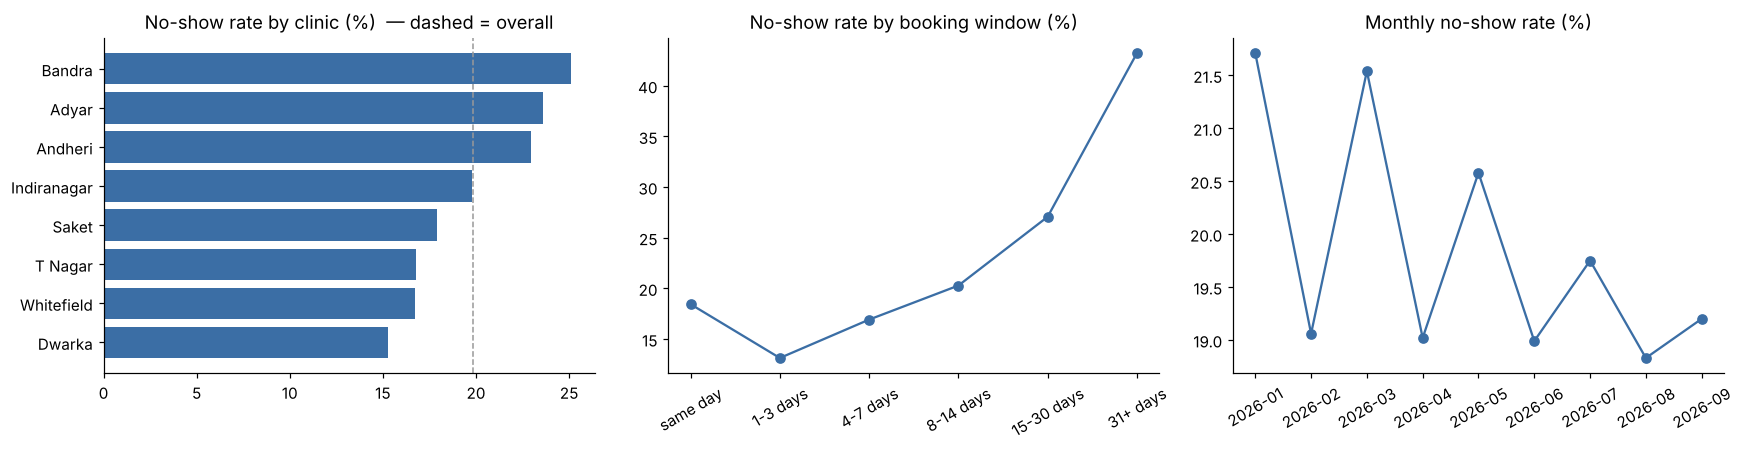

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
s = q02.sort_values("no_show_rate_pct")
ax[0].barh(s["clinic"].str.replace("CareClick ", ""), s["no_show_rate_pct"], color="#3b6ea5")
ax[0].axvline(q01["no_show_rate_pct"][0], color="#999", ls="--", lw=1)
ax[0].set(title="No-show rate by clinic (%)  — dashed = overall")
ax[1].plot(q04["lead_bucket"].str[3:], q04["no_show_rate_pct"], marker="o", color="#3b6ea5")
ax[1].set(title="No-show rate by booking window (%)")
ax[1].tick_params(axis="x", rotation=30)
ax[2].plot(q05["month"], q05["no_show_rate_pct"], marker="o", color="#3b6ea5")
ax[2].set(title="Monthly no-show rate (%)")
ax[2].tick_params(axis="x", rotation=30)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "figures" / "02_sql_overview.png", dpi=130, bbox_inches="tight")

## 5. Findings (computed from the query results above)

In [15]:
worst, best = q02.iloc[0], q02.iloc[-1]
low_b, high_b = q04.loc[q04['no_show_rate_pct'].idxmin()], q04.loc[q04['no_show_rate_pct'].idxmax()]
top_in_city = q06[q06["rank_in_city"] == 1][["city", "clinic", "no_show_rate_pct"]]
sms = q07.groupby("sms_received").apply(lambda g: np.average(g["no_show_rate_pct"], weights=g["total_appointments"]),
                                        include_groups=False)
rule = q10.set_index("segment")["no_show_rate_pct"]
print(f"1. Overall no-show rate is {q01['no_show_rate_pct'][0]}% ({int(q01['no_shows'][0]):,} of {int(q01['total_appointments'][0]):,} bookings).")
print(f"2. Highest clinic: {worst['clinic']} ({worst['no_show_rate_pct']}%); lowest: {best['clinic']} ({best['no_show_rate_pct']}%).")
print(f"3. Lead time matters: lowest no-show rate is for {low_b['lead_bucket'][3:]} bookings ({low_b['no_show_rate_pct']}%), highest for {high_b['lead_bucket'][3:]} bookings ({high_b['no_show_rate_pct']}%).")
print(f"4. Weighted no-show rate with an SMS reminder: {sms[1]:.1f}% vs without: {sms[0]:.1f}%.")
print(f"5. Rule 'past no-shows >= 2 AND lead >= 8 days AND no SMS' flags a segment with {rule['rule-flagged risky']}% no-shows vs {rule['not flagged']}% for the rest.")
print("6. Worst clinic in each city:")
print(top_in_city.to_string(index=False))

1. Overall no-show rate is 19.83% (2,372 of 11,964 bookings).
2. Highest clinic: CareClick Bandra (25.11%); lowest: CareClick Dwarka (15.27%).
3. Lead time matters: lowest no-show rate is for 1-3 days bookings (13.13%), highest for 31+ days bookings (43.22%).
4. Weighted no-show rate with an SMS reminder: 16.4% vs without: 23.7%.
5. Rule 'past no-shows >= 2 AND lead >= 8 days AND no SMS' flags a segment with 57.33% no-shows vs 18.86% for the rest.
6. Worst clinic in each city:
     city                clinic  no_show_rate_pct
Bengaluru CareClick Indiranagar             19.76
  Chennai       CareClick Adyar             23.58
    Delhi       CareClick Saket             17.88
   Mumbai      CareClick Bandra             25.11


In [16]:
if not USE_MYSQL:
    print("Note: these results came from the SQLite fallback. Set MYSQL_USER / MYSQL_PASSWORD in .env and re-run to use MySQL.")
conn.close()

Note: these results came from the SQLite fallback. Set MYSQL_USER / MYSQL_PASSWORD in .env and re-run to use MySQL.
